display_img shape = (120, 160) dtype = uint8


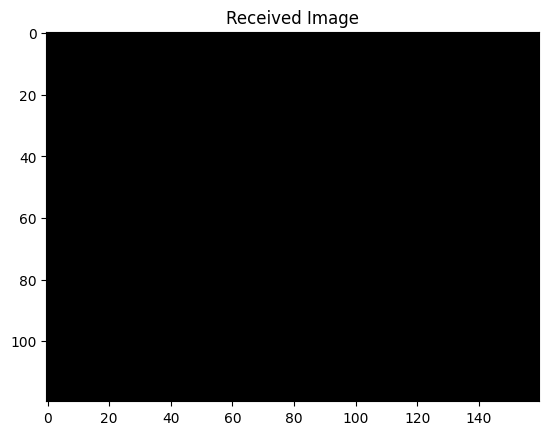

收到一幀圖像
本幀接收到的字節數：19201


KeyboardInterrupt: 

In [1]:
import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

class ImagePacketDecoder:
    """
    解析固定大小图像包，每包第一个字节为 0xFF，剩余为 u8 像素数据。
    """
    def __init__(self, width, height):
        self.width = width
        self.height = height
        self.packet_size = width * height + 1  # 包头 + 像素数据
        self.reset()

    def reset(self):
        """重置解析状态"""
        self.state = "WAIT_HEADER"
        self.buffer = np.zeros(self.width * self.height, dtype=np.uint8)
        self.addr = 0

    def feed_byte(self, byte):
        """逐字节解析数据"""
        if self.state == "WAIT_HEADER":
            if byte == 0xFF:
                self.state = "RECEIVE_DATA"
            return None

        elif self.state == "RECEIVE_DATA":
            self.buffer[self.addr] = byte
            self.addr += 1

            if self.addr >= self.buffer.size:
                img = self.buffer.reshape((self.height, self.width))
                self.reset()
                return img  # 直接返回 u8 图像

        return None


def load_calibration_frame(path, width, height):
    """从文本文件加载标定帧"""
    with open(path, "r") as f:
        hex_values = f.read().strip().split()
    raw_u8 = np.array([int(h, 16) for h in hex_values], dtype=np.uint8)
    return raw_u8.reshape((height, width))


def run_uart_in_notebook(port="COM8", baud=115200, 
                         width=160, height=120, enable_calibration=True,
                         save_calibration=False):
    decoder = ImagePacketDecoder(width, height)
    
    if enable_calibration:
        calib_img = load_calibration_frame("1-frame.txt", width, height)

    with serial.Serial(port, baud, timeout=0.01) as ser:
        print("等待圖像幀...")
        byte_count = 0

        while True:
            raw = ser.read(1)
            if not raw:
                continue

            byte_count += 1
            img = decoder.feed_byte(raw[0])
            
            if img is not None:
                if enable_calibration:
                    corrected = img.astype(np.int16) - calib_img.astype(np.int16)
                    corrected = np.clip(corrected, 0, 255).astype(np.uint8)
                    display_img = corrected
                else:
                    display_img = img
                
                if save_calibration:
                    with open("calibration_frame.txt", "w") as f:
                        for val in img.flatten():
                            f.write(f"{val:02X} ")
                    print("已保存当前帧为标定文件：calibration_frame.txt")

                clear_output(wait=True)
                print("display_img shape =", display_img.shape, "dtype =", display_img.dtype)
                plt.imshow(display_img, cmap="gray")
                plt.title("Received Image")
                plt.show()

                print("收到一幀圖像")
                print(f"本幀接收到的字節數：{byte_count}")
                byte_count = 0

run_uart_in_notebook("COM31", 5000000, 160, 120, enable_calibration=False, save_calibration=False)